# 46 · Policy gradients from scratch: REINFORCE on the MuJoCo cart-pole, with and without a baseline

In [1]:
import numpy as np, torch, torch.nn as nn, matplotlib.pyplot as plt
from vlacourse.rl_envs import CartPoleEnv
from vlacourse import show_video

def mlp(i, o, h=64):
    return nn.Sequential(nn.Linear(i, h), nn.Tanh(), nn.Linear(h, h), nn.Tanh(), nn.Linear(h, o))

def rollout(env, policy, seed):
    obs, _ = env.reset(seed=seed); O, A, R = [], [], []
    done = False
    while not done:
        with torch.no_grad():
            a = torch.distributions.Categorical(logits=policy(torch.tensor(obs))).sample().item()
        O.append(obs); A.append(a)
        obs, r, te, tr, _ = env.step(a); R.append(r); done = te or tr
    return np.array(O), np.array(A), np.array(R)

def returns_to_go(R, gamma):
    G, out = 0.0, np.zeros_like(R)
    for t in reversed(range(len(R))):
        G = R[t] + gamma * G; out[t] = G
    return out

def train(baseline, iters=150, batch_eps=10, gamma=0.99, seed=0):
    torch.manual_seed(seed); env = CartPoleEnv()
    pi, V = mlp(4, 2), mlp(4, 1)
    opt_pi, opt_v = torch.optim.Adam(pi.parameters(), 3e-3), torch.optim.Adam(V.parameters(), 1e-2)
    curve, grad_vars = [], []
    for it in range(iters):
        eps = [rollout(env, pi, seed * 10 ** 5 + it * batch_eps + k) for k in range(batch_eps)]
        O = torch.tensor(np.concatenate([e[0] for e in eps])); A = torch.tensor(np.concatenate([e[1] for e in eps]))
        G = torch.tensor(np.concatenate([returns_to_go(e[2], gamma) for e in eps]), dtype=torch.float32)
        adv = G - V(O).squeeze(-1).detach() if baseline else G
        logp = torch.distributions.Categorical(logits=pi(O)).log_prob(A)
        per_sample = []
        if it % 10 == 0:
            for k in range(0, len(O), max(1, len(O) // 20)):
                pi.zero_grad(); (-(logp[k] * adv[k])).backward(retain_graph=True)
                per_sample.append(torch.cat([p.grad.flatten() for p in pi.parameters()]).clone())
            grad_vars.append(torch.stack(per_sample).var(0).mean().item())
        loss = -(logp * adv).mean()
        opt_pi.zero_grad(); loss.backward(); opt_pi.step()
        if baseline:
            for _ in range(5):
                v_loss = ((V(O).squeeze(-1) - G) ** 2).mean()
                opt_v.zero_grad(); v_loss.backward(); opt_v.step()
        curve.append(np.mean([len(e[2]) for e in eps]))
    return pi, np.array(curve), np.array(grad_vars)

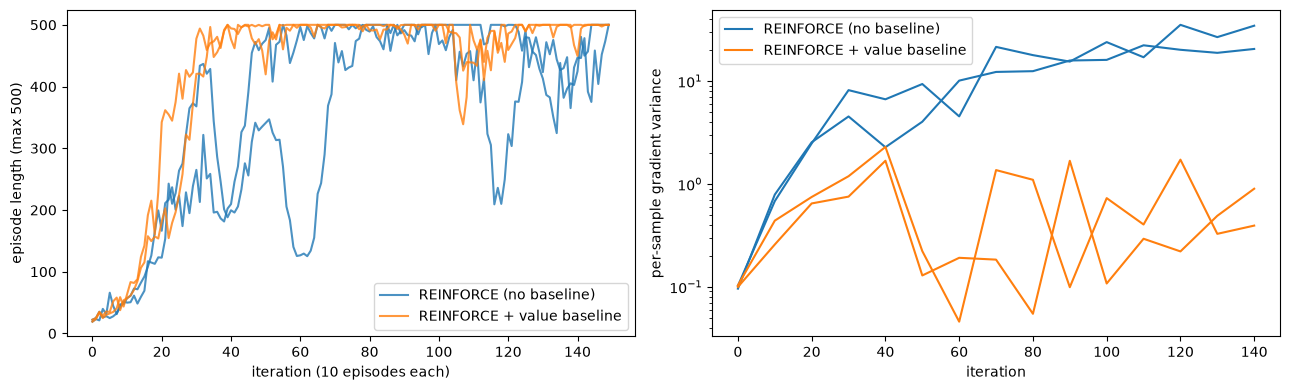

In [2]:
runs = {b: [train(b, seed=s) for s in range(2)] for b in [False, True]}
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for b, rs in runs.items():
    lab = "REINFORCE + value baseline" if b else "REINFORCE (no baseline)"
    for k, (_, c, gv) in enumerate(rs):
        ax[0].plot(c, color="C1" if b else "C0", alpha=0.8, label=lab if k == 0 else None)
        ax[1].semilogy(np.arange(len(gv)) * 10, gv, color="C1" if b else "C0", label=lab if k == 0 else None)
ax[0].set_xlabel("iteration (10 episodes each)"); ax[0].set_ylabel("episode length (max 500)"); ax[0].legend()
ax[1].set_xlabel("iteration"); ax[1].set_ylabel("per-sample gradient variance"); ax[1].legend(); plt.tight_layout(); plt.show()

greedy policy balanced for 500 steps


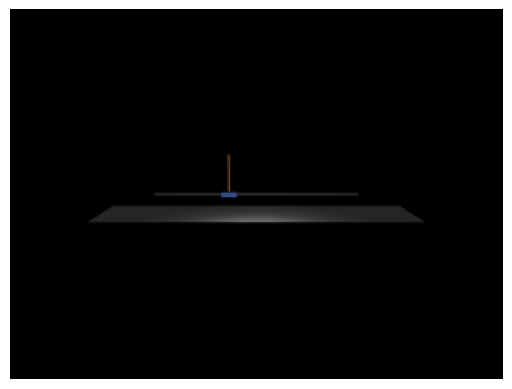

In [3]:
pi = runs[True][0][0]
env = CartPoleEnv(); obs, _ = env.reset(seed=123); frames = []
for t in range(500):
    with torch.no_grad():
        a = pi(torch.tensor(obs)).argmax().item()
    obs, r, te, tr, _ = env.step(a)
    if t % 3 == 0:
        frames.append(env.render())
    if te or tr:
        break
print("greedy policy balanced for", t + 1, "steps")
show_video(frames, fps=30, title="REINFORCE cart-pole")
plt.imshow(frames[-1]); plt.axis("off"); plt.show()